In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from tqdm import tqdm
from inference_tools import ParticleFilter, crng, HilbertSorter, ConditionedBridge
from matplotlib import patches as mpatches
import matplotlib as mpl
from matplotlib import cm as cm
mpl.rcParams['figure.dpi'] = 300

#plt.style.use('dark_background')

In [2]:
sorter = HilbertSorter(depth=9, dims=2)
bridge_gen = ConditionedBridge()

In [15]:
def abp_sde(T0, T1, X0, params):
    
    output_hires = params.get('output_hires', False)
    omit_bridges = params.get('omit_bridges', False)
    
    target_shift_X = params.get('target_shift_X', 0)
    target_shift_Y = params.get('target_shift_Y', 0)
    target_shift_P = params.get('target_shift_PHI', 0)
    target_slope_X = params.get('target_slope_X', 0)
    target_slope_Y = params.get('target_slope_Y', 0)
    target_slope_P = params.get('target_slope_PHI', 0)
    
    BridgeGen = params['BridgeGen']
    RNG = params['RNG']
    Dt  = params['Dt']
    Dr  = params['Dr']
    v   = params['v']
    _id = params.get('id', -1)
    
    dt  = params['dt']
    
    D = np.array([Dt, Dt, Dr])
    
    X = X0.copy()
    T = T0
    step = 0
    
    if output_hires:
        hires  = [X.copy()]
        hiresT = [T]
        
    n_steps = int((T1 - T0) / dt + 1)
    n_parts = X.shape[0]
    dt_ = (T1 - T0) / n_steps
    
    if not omit_bridges:
        
        offset_factor = 1 / (np.sqrt(Dr * dt_) * v) * n_steps
        
        shiftX = RNG.get(('abpsdeXshift', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_shift_X
        shiftY = RNG.get(('abpsdeYshift', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_shift_Y
        shiftP = RNG.get(('abpsdePshift', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_shift_P * offset_factor
        
        slopeX = RNG.get(('abpsdeXslope', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_slope_X
        slopeY = RNG.get(('abpsdeYslope', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_slope_Y
        slopeP = RNG.get(('abpsdePslope', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_slope_P * offset_factor
        
        bridge_res_X = BridgeGen.get(n_steps + 1, shiftX, slopeX, ('abpsdeXbridgegen', _id, T0, T1), 0.0, RNG)
        bridge_res_Y = BridgeGen.get(n_steps + 1, shiftY, slopeY, ('abpsdeYbridgegen', _id, T0, T1), 0.0, RNG)
        bridge_res_P = BridgeGen.get(n_steps + 1, shiftP, slopeP, ('abpsdePbridgegen', _id, T0, T1), 0.0, RNG)
        
        wX  = bridge_res_X['w']
        dwX = np.diff(wX, axis=0)
        dwX = np.concatenate([wX[[0],:], dwX])
        ddX = np.diff(dwX, axis=0).T
        
        wY  = bridge_res_Y['w']
        dwY = np.diff(wY, axis=0)
        dwY = np.concatenate([wY[[0],:], dwY])
        ddY = np.diff(dwY, axis=0).T
        
        wP  = bridge_res_P['w']
        dwP = np.diff(wP, axis=0)
        dwP = np.concatenate([wP[[0],:], dwP])
        ddP = np.diff(dwP, axis=0).T

        w = np.stack([ddX, ddY, ddP], axis=1)
        
    else:
        
        w = RNG.get(('abpsde_full', _id, T0, T1), (n_parts, 3, n_steps), corr=0) 

    for k in range(n_steps):

        ''' Integrate the EOM '''

        dx = np.cos(X[:, 2])
        dy = np.sin(X[:, 2])
        drift = np.stack([dx*v, dy*v, np.zeros_like(dx)], axis=1)

        X += np.sqrt(dt_) * w[..., k] * np.sqrt(D)
        X += dt_ * drift
        
        if output_hires:
            hires.append(X.copy())
            hiresT.append(T)
    
    res_dict = dict(X1=X, logl=0.)
    
    if output_hires:
        res_dict['per_particle_streams'] = dict(hires=np.stack(hires, -1))

    return res_dict

# Simple ABP

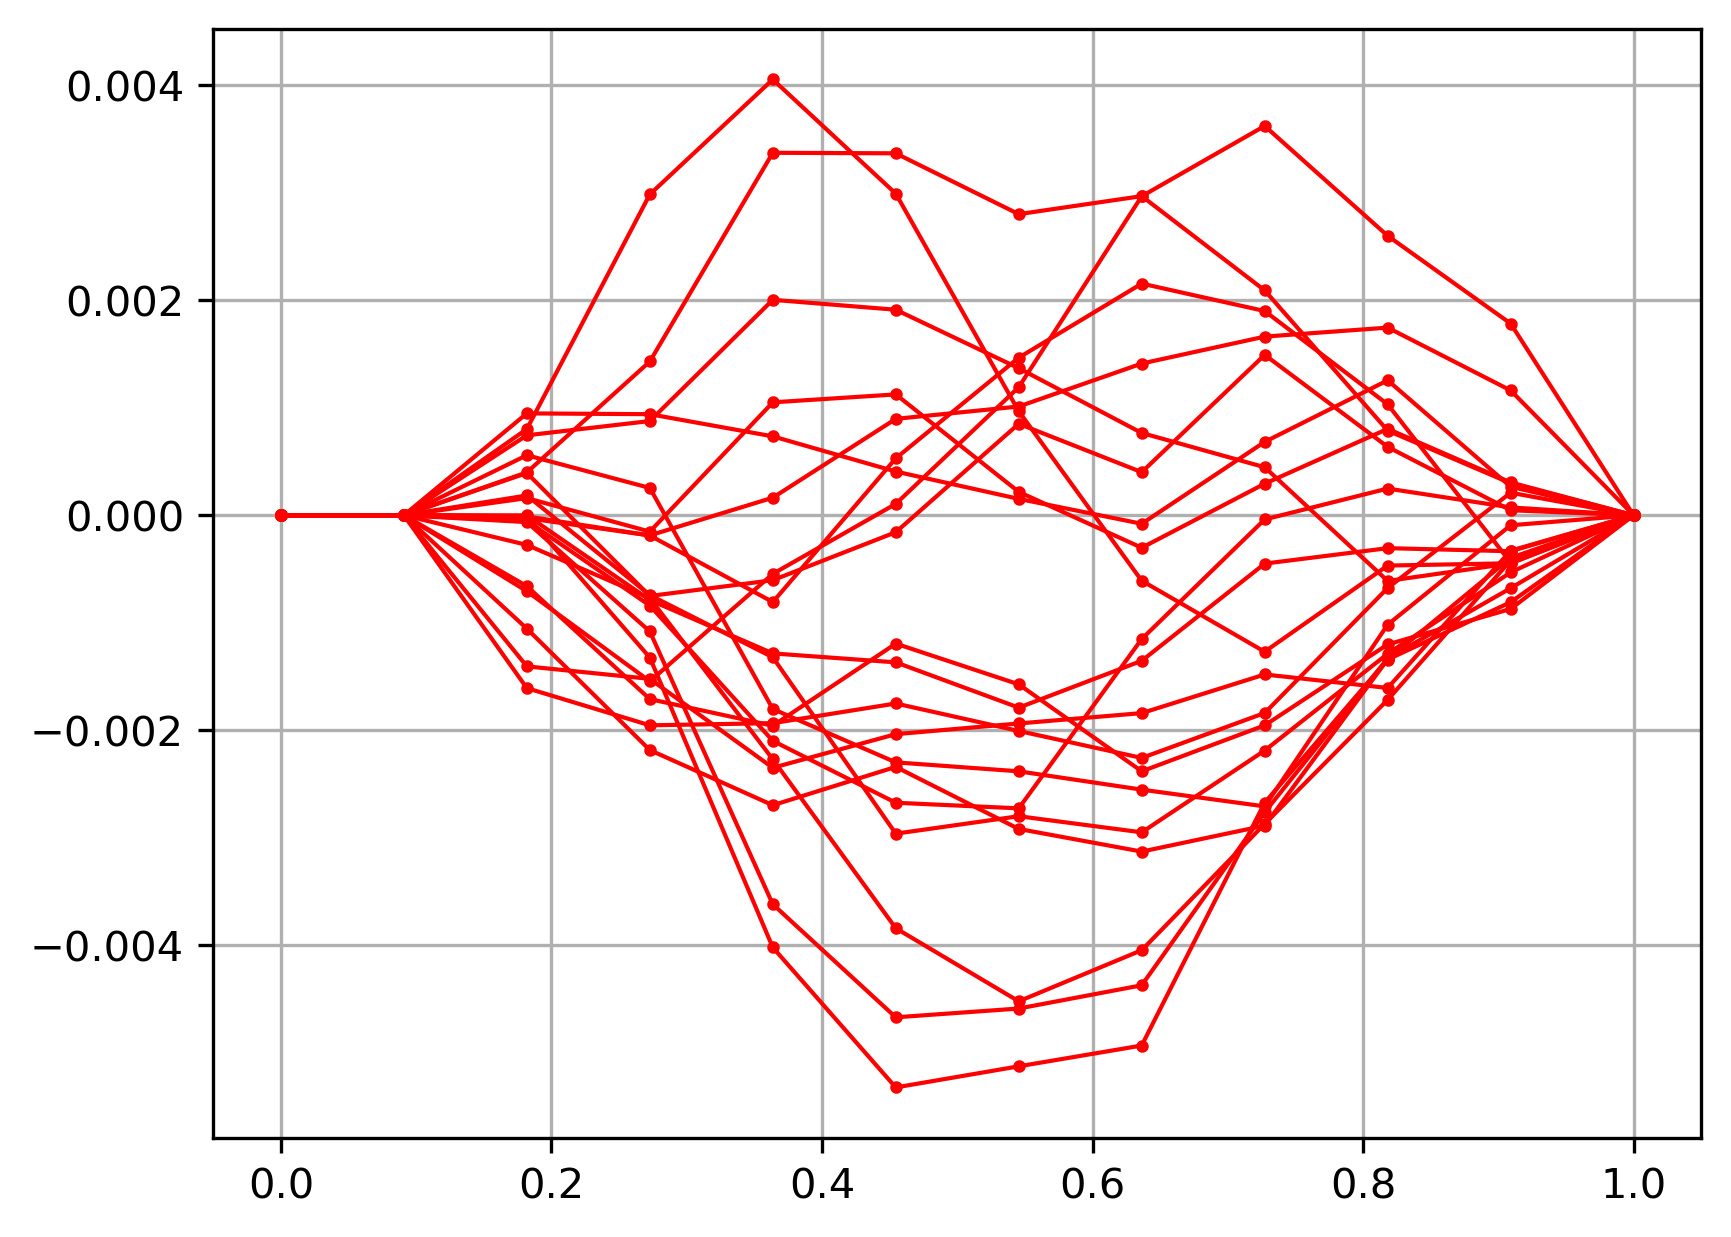

In [16]:
N = 20
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.001,
              v = 1,
              dt = 1e-1,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1.T,y1.T, 'o-r', linewidth=1, alpha=1, markersize=2)
#plt.gca().axis('equal')
plt.grid()
plt.show()

# The other stuff

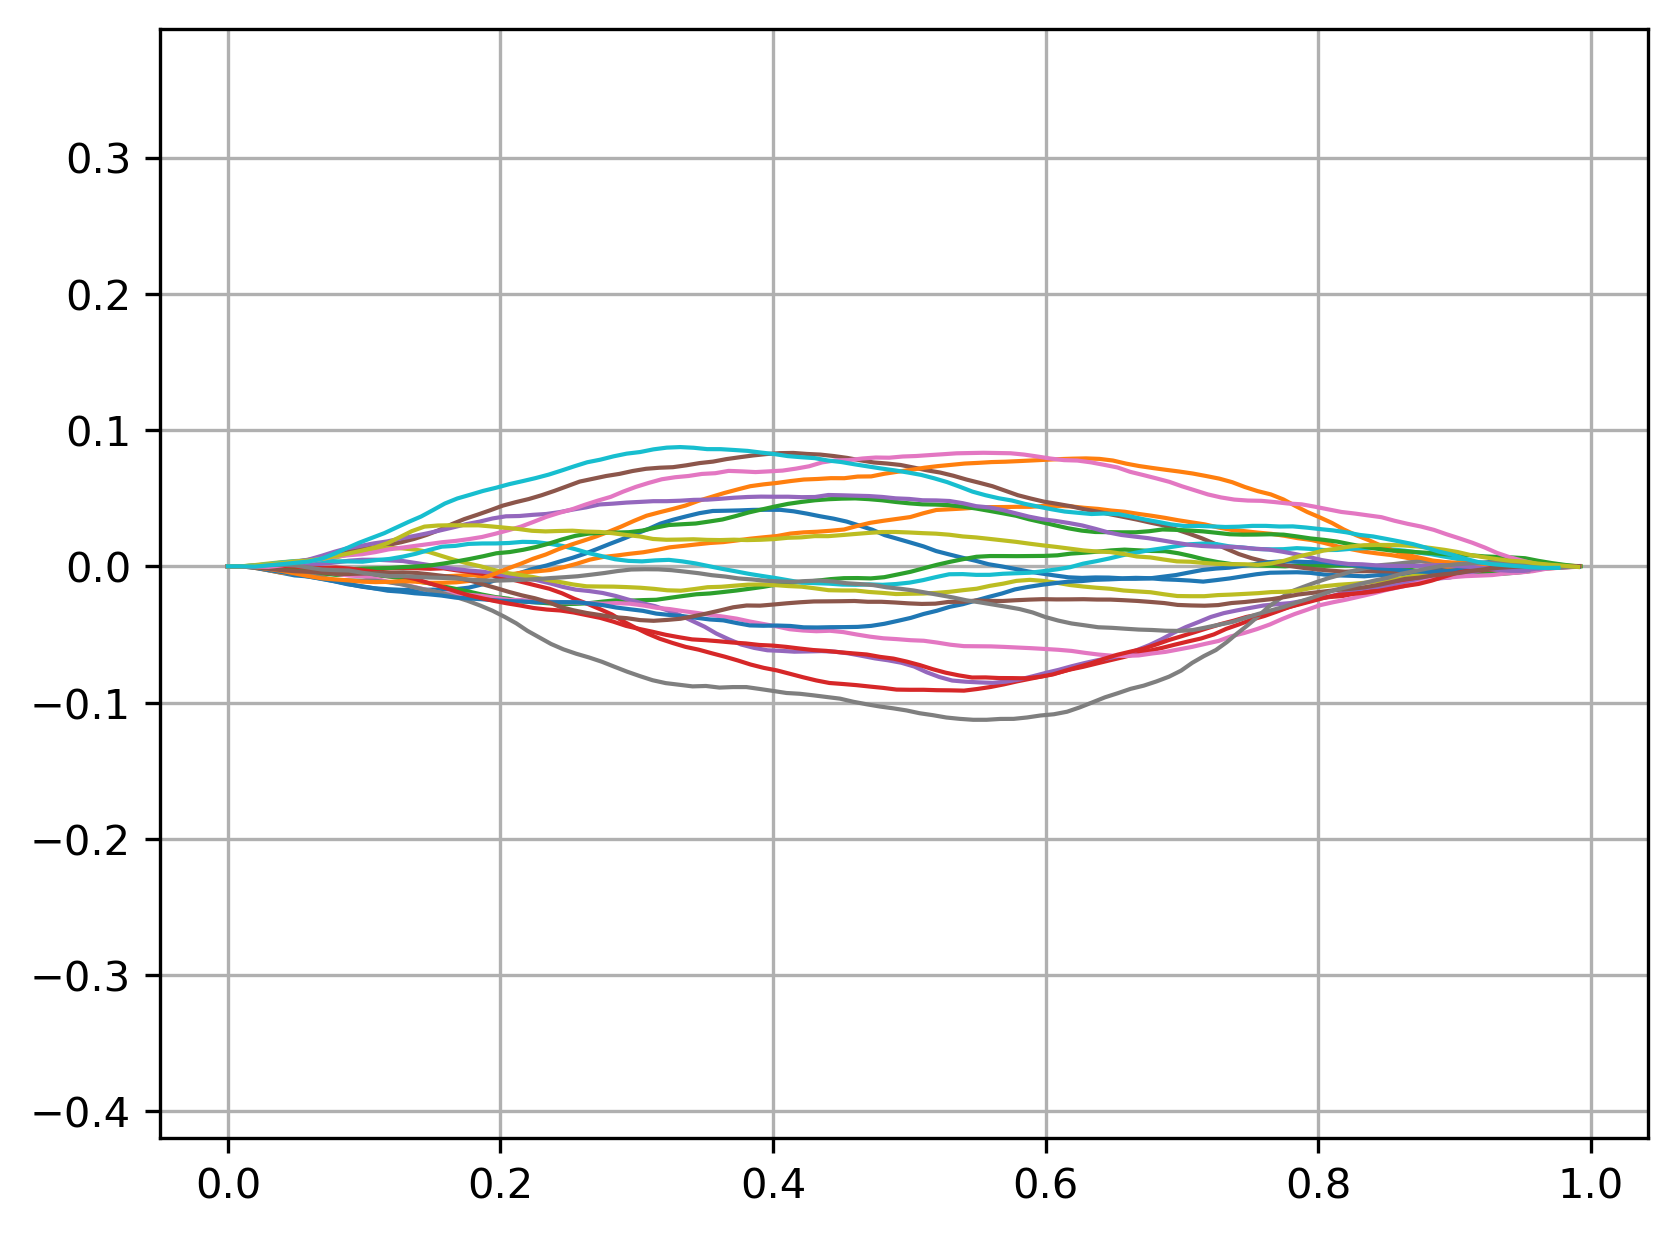

In [17]:
N = 20
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.4,
              v = 1,
              dt = 1e-2,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1.T,y1.T, linewidth=1, alpha=1, markersize=2)
plt.gca().axis('equal')
plt.grid()
plt.show()

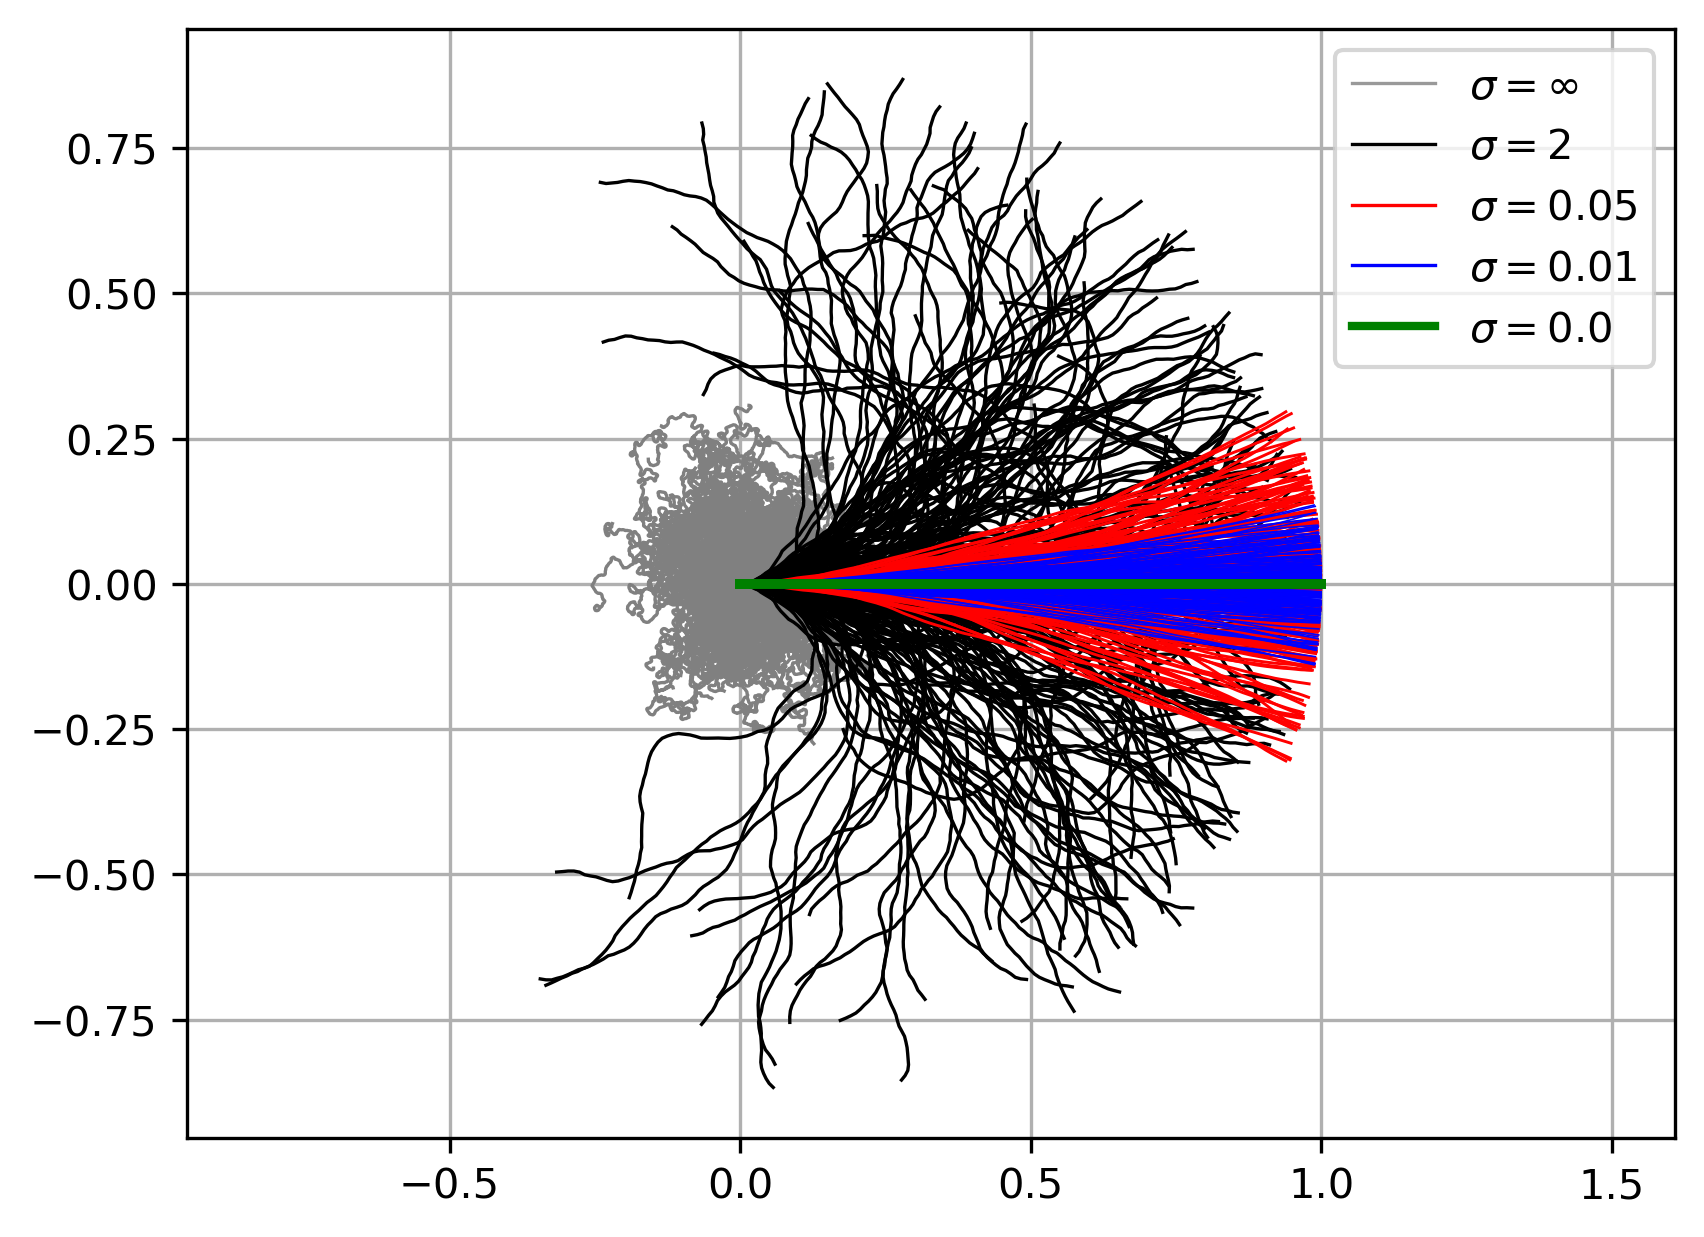

In [18]:
N = 200
X0 = np.zeros((N, 3)) + [0,0,0]


params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 200,
              v = 1,
              dt = 1e-4,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1.T,y1.T, linewidth=0.8, alpha=1, markersize=2, color='grey')
plt.plot(x1.T[0],y1.T[0], linewidth=0.8, alpha=0.8, markersize=2, color='grey', label=f'$\sigma=\infty$')

params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 2,
              v = 1,
              dt = 1e-2,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1.T,y1.T, linewidth=0.8, alpha=1, markersize=2, color='k')
plt.plot(x1.T[0],y1.T[0], linewidth=0.8, alpha=1, markersize=2, color='k', label=f'$\sigma={params["Dr"]}$')

params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.05,
              v = 1,
              dt = 1e-2,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1.T,y1.T, linewidth=0.7, alpha=1, markersize=2, color='r')
plt.plot(x1.T[0],y1.T[0], linewidth=0.8, alpha=1, markersize=2, color='r', label=f'$\sigma={params["Dr"]}$')

params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.01,
              v = 1,
              dt = 1e-2,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1.T,y1.T, linewidth=0.4, alpha=1, markersize=2, color='b')
plt.plot(x1.T[0],y1.T[0], linewidth=0.8, alpha=1, markersize=2, color='b', label=f'$\sigma={params["Dr"]}$')

params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.0,
              v = 1,
              dt = 1e-2,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1.T,y1.T, linewidth=2, alpha=1, markersize=2, color='g')
plt.plot(x1.T[0],y1.T[0], linewidth=2, alpha=1, markersize=2, color='g', label=f'$\sigma={params["Dr"]}$')


plt.gca().axis('equal')
plt.legend()
plt.grid()
plt.savefig("img/ballistic_uncond_1.png")
plt.show()

In [19]:
N = 1000
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 10,
              v = 1,
              dt = 1e-3,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              
             )
params['target_slope_PHI'] = 1
params['target_shift_PHI'] = 0
sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
sim_res = abp_sde(0, 1, X0, params)

x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]

In [20]:
params['RNG'].reroll(0.9)
#params['target_shift_PHI'] = 0.1
#params['target_slope_PHI'] = 0
#params['v'] *= 1.3
sim_res = abp_sde(0, 1, X0, params)
x2 = sim_res['per_particle_streams']['hires'][:,0,:]
y2 = sim_res['per_particle_streams']['hires'][:,1,:]

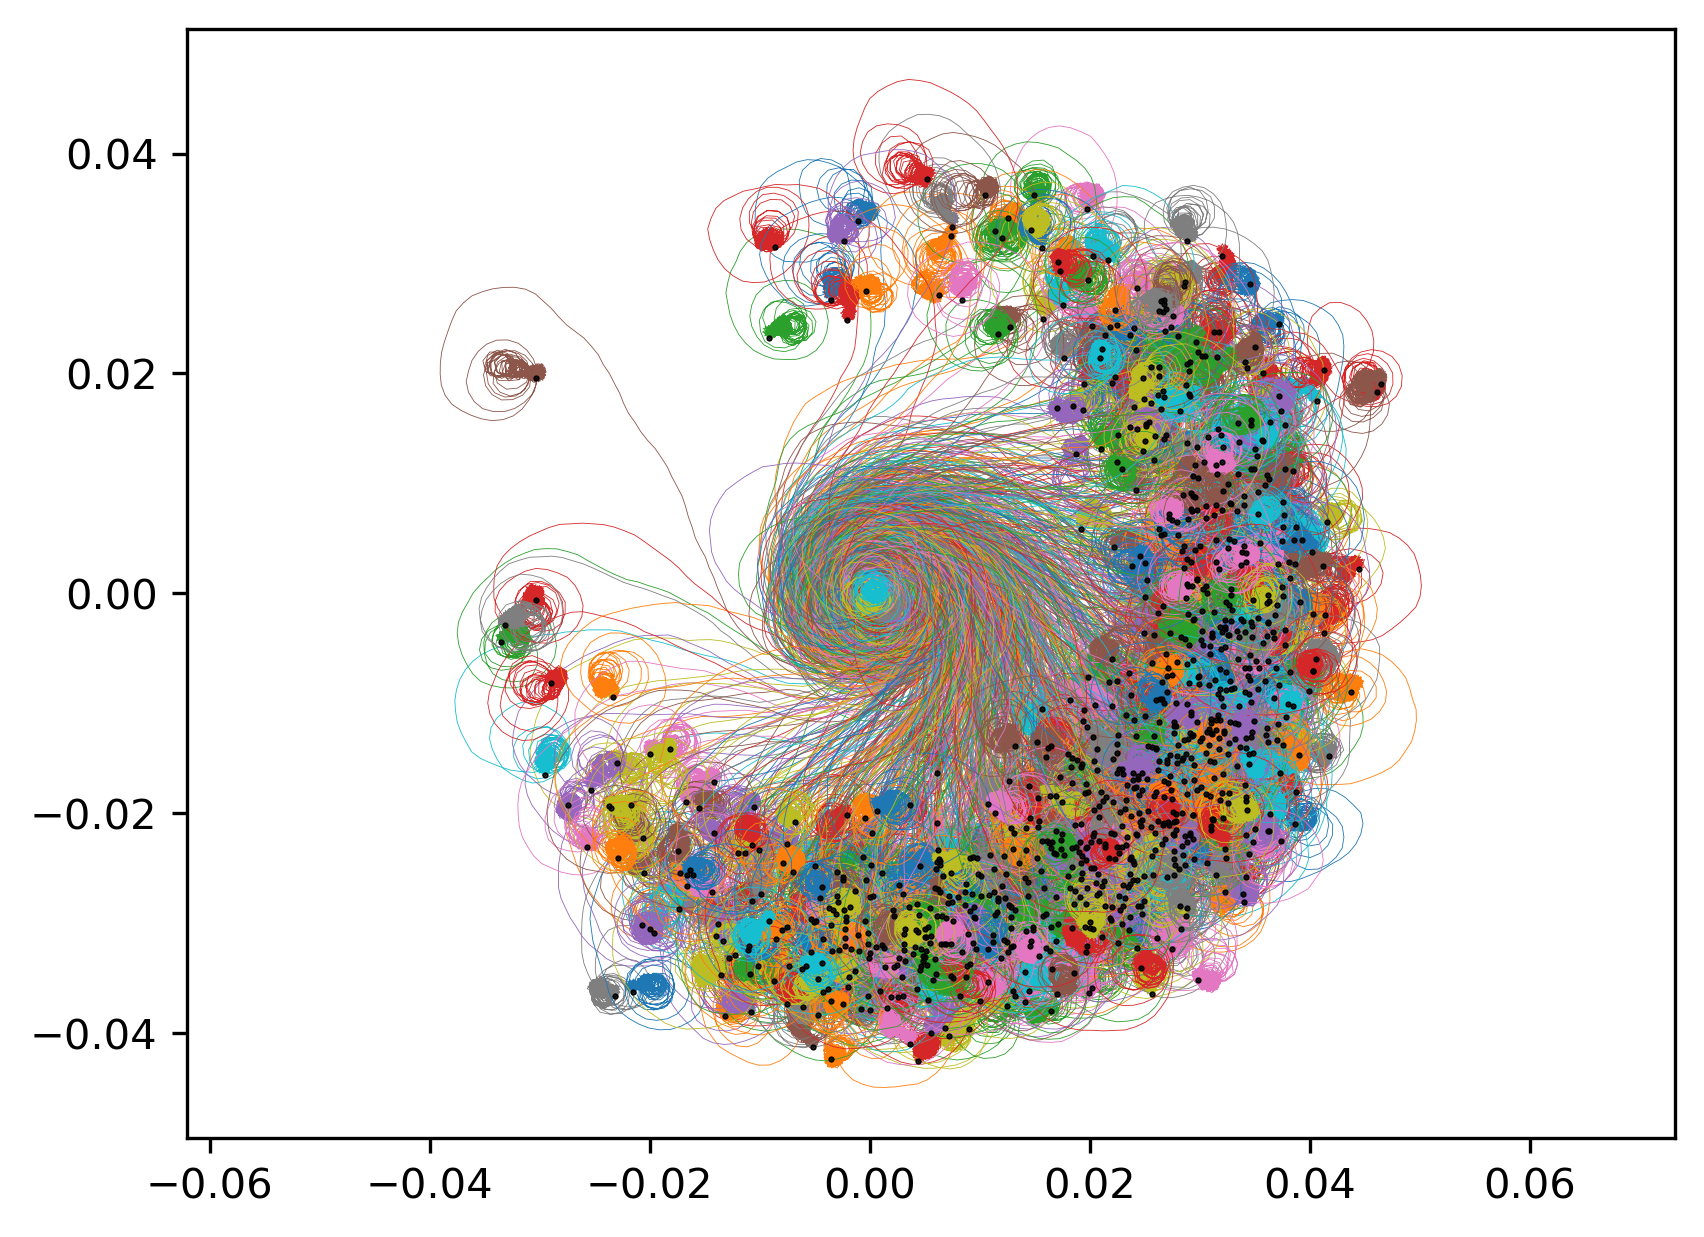

In [21]:
plt.plot(x1.T,y1.T, linewidth=0.2, alpha=1)
plt.plot(x1[...,-1].T,y1[...,-1].T, '.k', markersize=1)
#plt.plot(x2.T,y2.T, 'g', linewidth=1, alpha=1)
#plt.plot(x2[...,-1].T,y2[...,-1].T, '.w', markersize=2)
plt.gca().axis('equal')
#plt.ylim([-0.5,0.1])
plt.show()

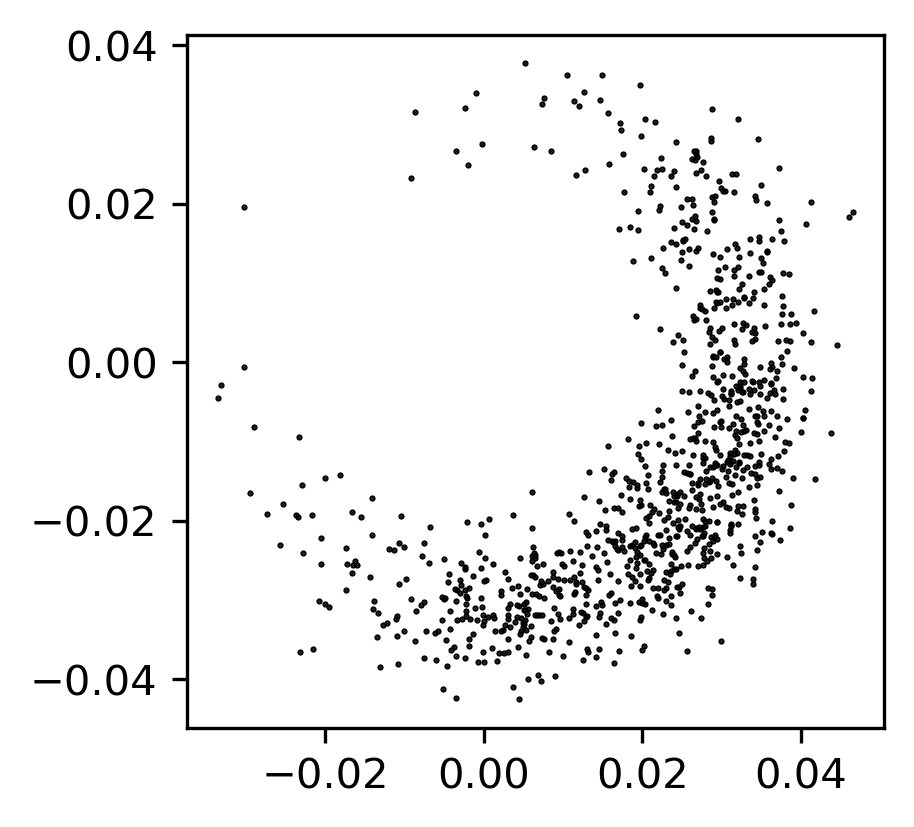

In [22]:
plt.figure(figsize=(3,3))
plt.plot(x1[...,-1].T, y1[...,-1].T, '.k', markersize=1)
#plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.g', markersize=3)
plt.gca().axis('equal')
plt.show()

In [23]:
def abp_logl(X, Y, params):
    sigma = params['sigma_observation']
    return np.nansum( -((X - Y) / sigma) ** 2, axis=1)

In [24]:
N = 100
X0 = np.zeros((N, 3)) + [0,0,0] + 0 * np.random.randn(N, 3) * [0.01, 0.01, np.pi/20]

In [25]:
Yorient_orig = [dict(T=1, Y=[1, .5,  np.nan], target_shift_PHI=0, target_slope_PHI=0.0),
                dict(T=2, Y=[2, 1, np.nan], target_shift_PHI=0., target_slope_PHI=0),
                #dict(T=4, Y=[4, -0.,  np.nan], target_shift_PHI=-.0, target_slope_PHI=0),
          ]

params_orig = dict(RNG=crng(121),
              Dt = 0,
              Dr = 1e-2,
              v = 1,
              dt = 1e-2,
              HilbertSort_dims = (0,1),
              HilbertSorter = sorter,
              sigma_observation = 4e-2,
              output_hires=True,
              output_trajectory=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              HilbertSort_useObservationCenter = False,
              observation_parameters = ['target_shift_PHI', 'target_slope_PHI'],
              observation_parameter_adapt_rate = dict(target_shift_PHI=0.005, target_slope_PHI=0.0001)
             )

  0%|                                                  | 0/1000 [00:00<?, ?it/s]~/PHD/Research/PMMH/inference_tools.py:120: RuntimeWarning: invalid value encountered in divide
  p = w / np.sum(w)                   # Normalized PDF
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
~/PHD/Research/PMMH/inference_tools.py:120: RuntimeWarning: invalid value encountered in divide
  p = w / np.sum(w)                   # Normalized PDF
100%|███████████████████████████████████████| 1000/1000 [00:15<00:00, 64.60it/s]


accept =  275
1.1270613254631068


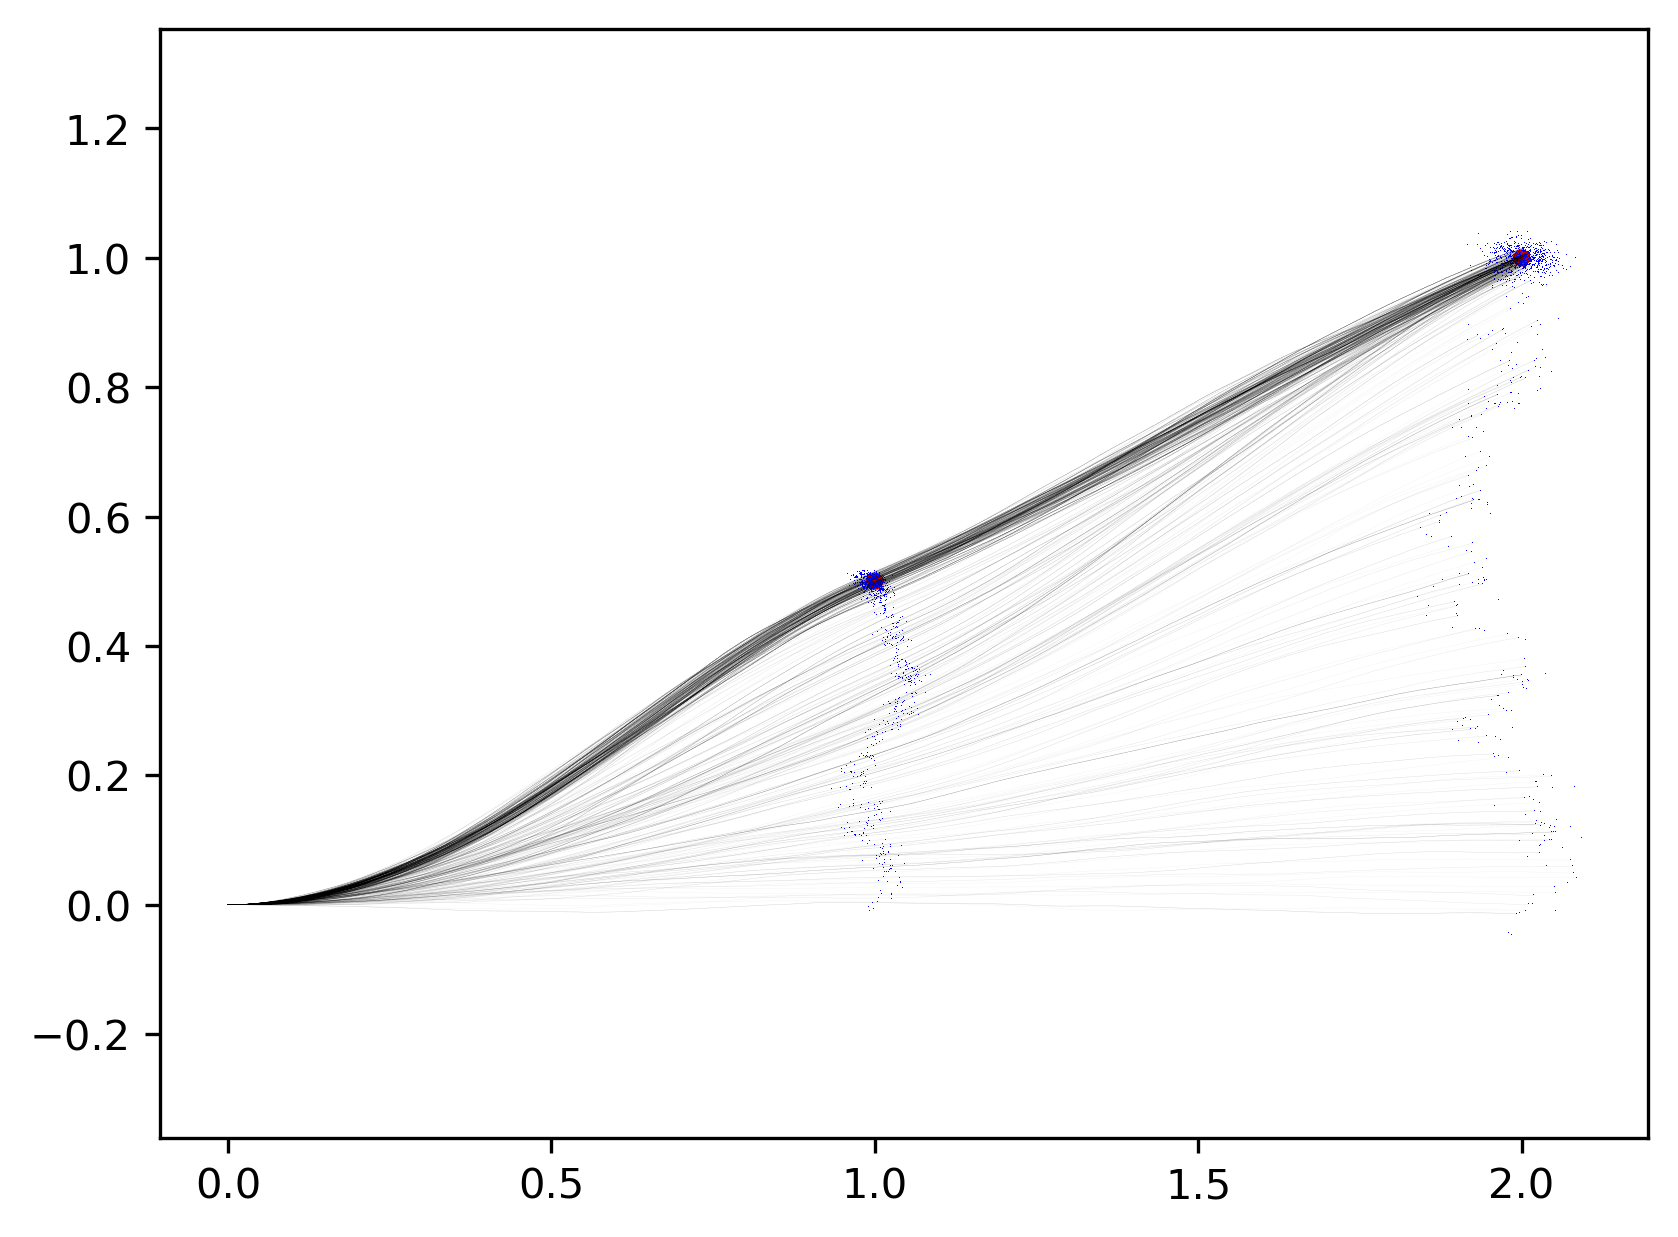

(array([ 74., 181., 218., 125.,  91.,  69.,  75., 112.,  30.,  25.]),
 array([0.0087299 , 0.00890823, 0.00908656, 0.00926489, 0.00944322,
        0.00962155, 0.00979988, 0.00997821, 0.01015654, 0.01033487,
        0.0105132 ]),
 <BarContainer object of 10 artists>)

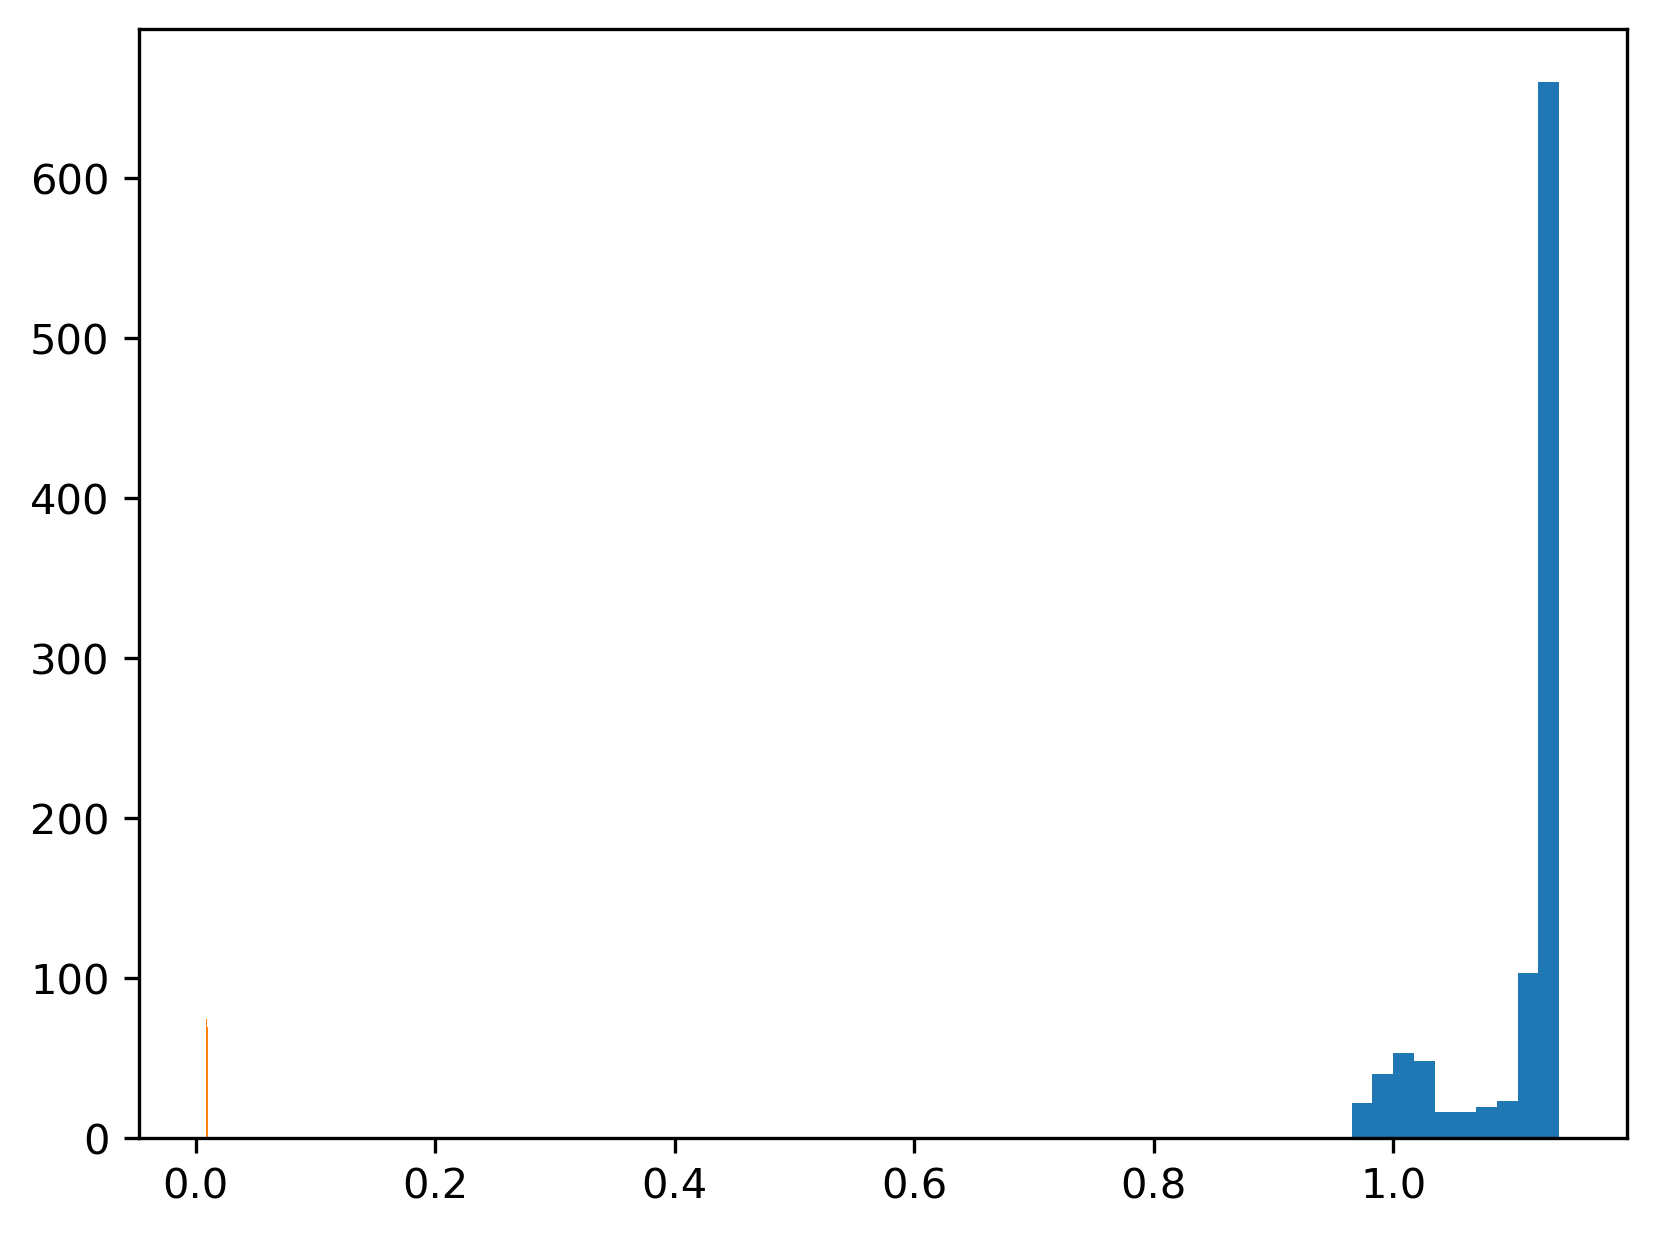

In [26]:
Yorient = Yorient_orig
params = params_orig

logl = -np.inf
accept = 0
params['sigma_observation'] = 1e-2
#params['target_shift_PHI'] = 0.001
#params['target_slope_PHI'] = 0.00001

Drpost = []
vpost = []

for _ in tqdm(range(1000)):
    params['RNG'].reroll()
    old_v = params['v']
    old_Dr = params['Dr']
    
    params['v'] *= (1 + np.random.randn() * 0.01)
    params['Dr'] *= (1 + np.random.randn() * 0.01)
    
    for param_name in params['observation_parameters']:
        for i, yt_ in enumerate(Yorient):
            Yorient[i][param_name + '_old'] = Yorient[i][param_name]
            Yorient[i][param_name] += np.random.randn() * params["observation_parameter_adapt_rate"][param_name]

    
    filt_res = ParticleFilter(abp_logl, abp_sde, X0, Yorient, params)
    
    logl_propose = filt_res['logl']
    a = np.random.rand()
    thresh = 1 if logl_propose > logl else np.exp(logl_propose - logl)
    if a > thresh:
        params['v'] = old_v
        
        for param_name in params['observation_parameters']:
            for i, yt_ in enumerate(Yorient):
                Yorient[i][param_name] = Yorient[i][param_name + '_old']
        
        params['Dr'] = old_Dr
        params['RNG'].revert()
    else:
        accept += 1
        logl = logl_propose
        r = filt_res['streams']['hires']
        
    filt_res['trajectory']
    plt.plot(r[0,:], r[1,:], 'k', alpha=0.05, linewidth=0.1)
    plt.plot(filt_res['trajectory'][0,:], filt_res['trajectory'][1,:], ',b')
    vpost.append(params['v'])
    Drpost.append(params['Dr'])
    
print("accept = ", accept)
#plt.gca().axis('equal')
for yt_ in Yorient:
    y = yt_['Y']
    circ = mpatches.Circle(y[:2], radius=params['sigma_observation'], color='r', zorder=0,)
    plt.gca().add_patch(circ)

plt.xlim([-0.1, 4.2])
print(params['v'])
#print(Yorient[1]['target_shift_PHI'])
#plt.ylim([-0.4, 0.6])
plt.gca().axis('equal')
plt.show()
plt.hist(vpost)
plt.hist(Drpost)

# Target Animation

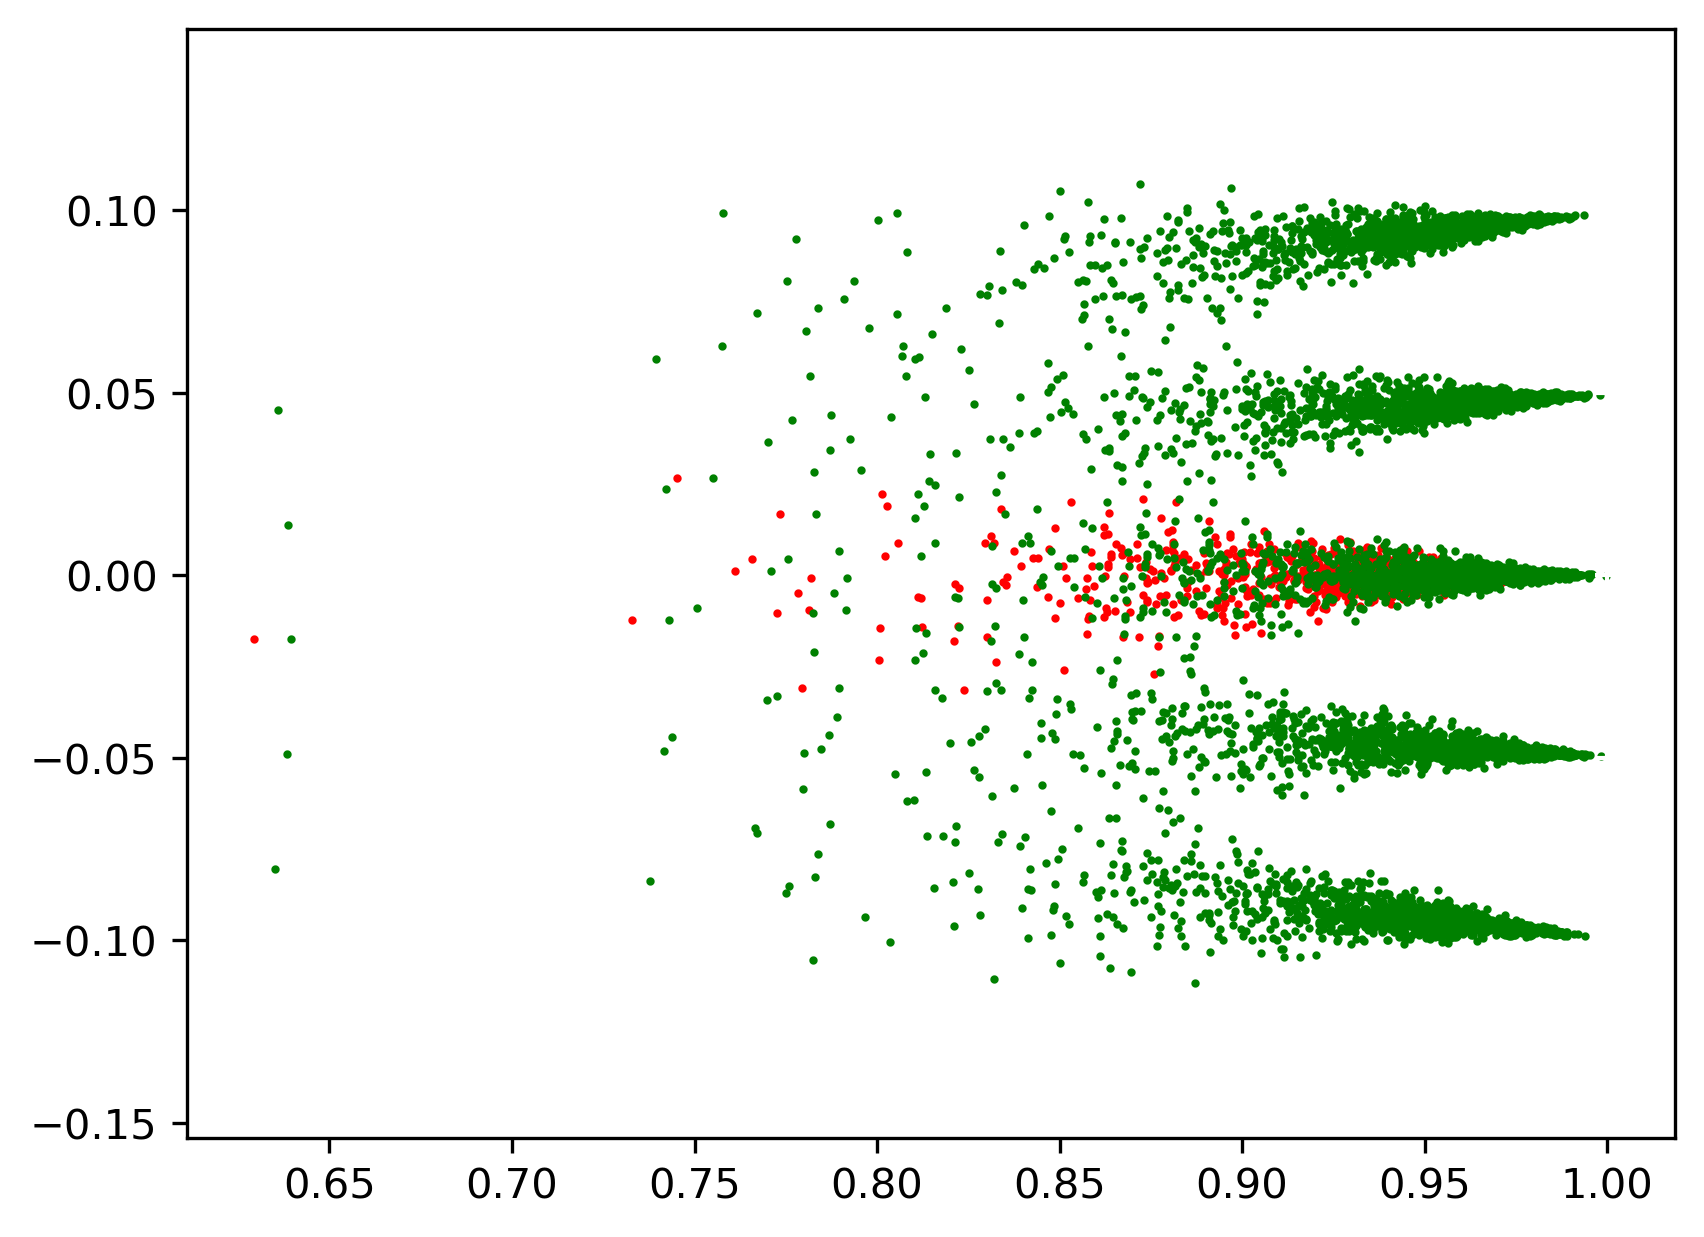

In [27]:
N = 1300
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 2,
              v = 1,
              dt = 1e-3,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1[...,-1].T, y1[...,-1].T, '.r', markersize=2)
for offset in np.linspace(-0.1,0.1, 5):  
    params['target_shift_PHI'] = offset
    sim_res = abp_sde(0, 1, X0, params)
    x2 = sim_res['per_particle_streams']['hires'][:,0,:]
    y2 = sim_res['per_particle_streams']['hires'][:,1,:]
    plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.g', markersize=2)
    plt.plot([1],[offset], '+w')
    plt.gca().axis('equal')
plt.show()

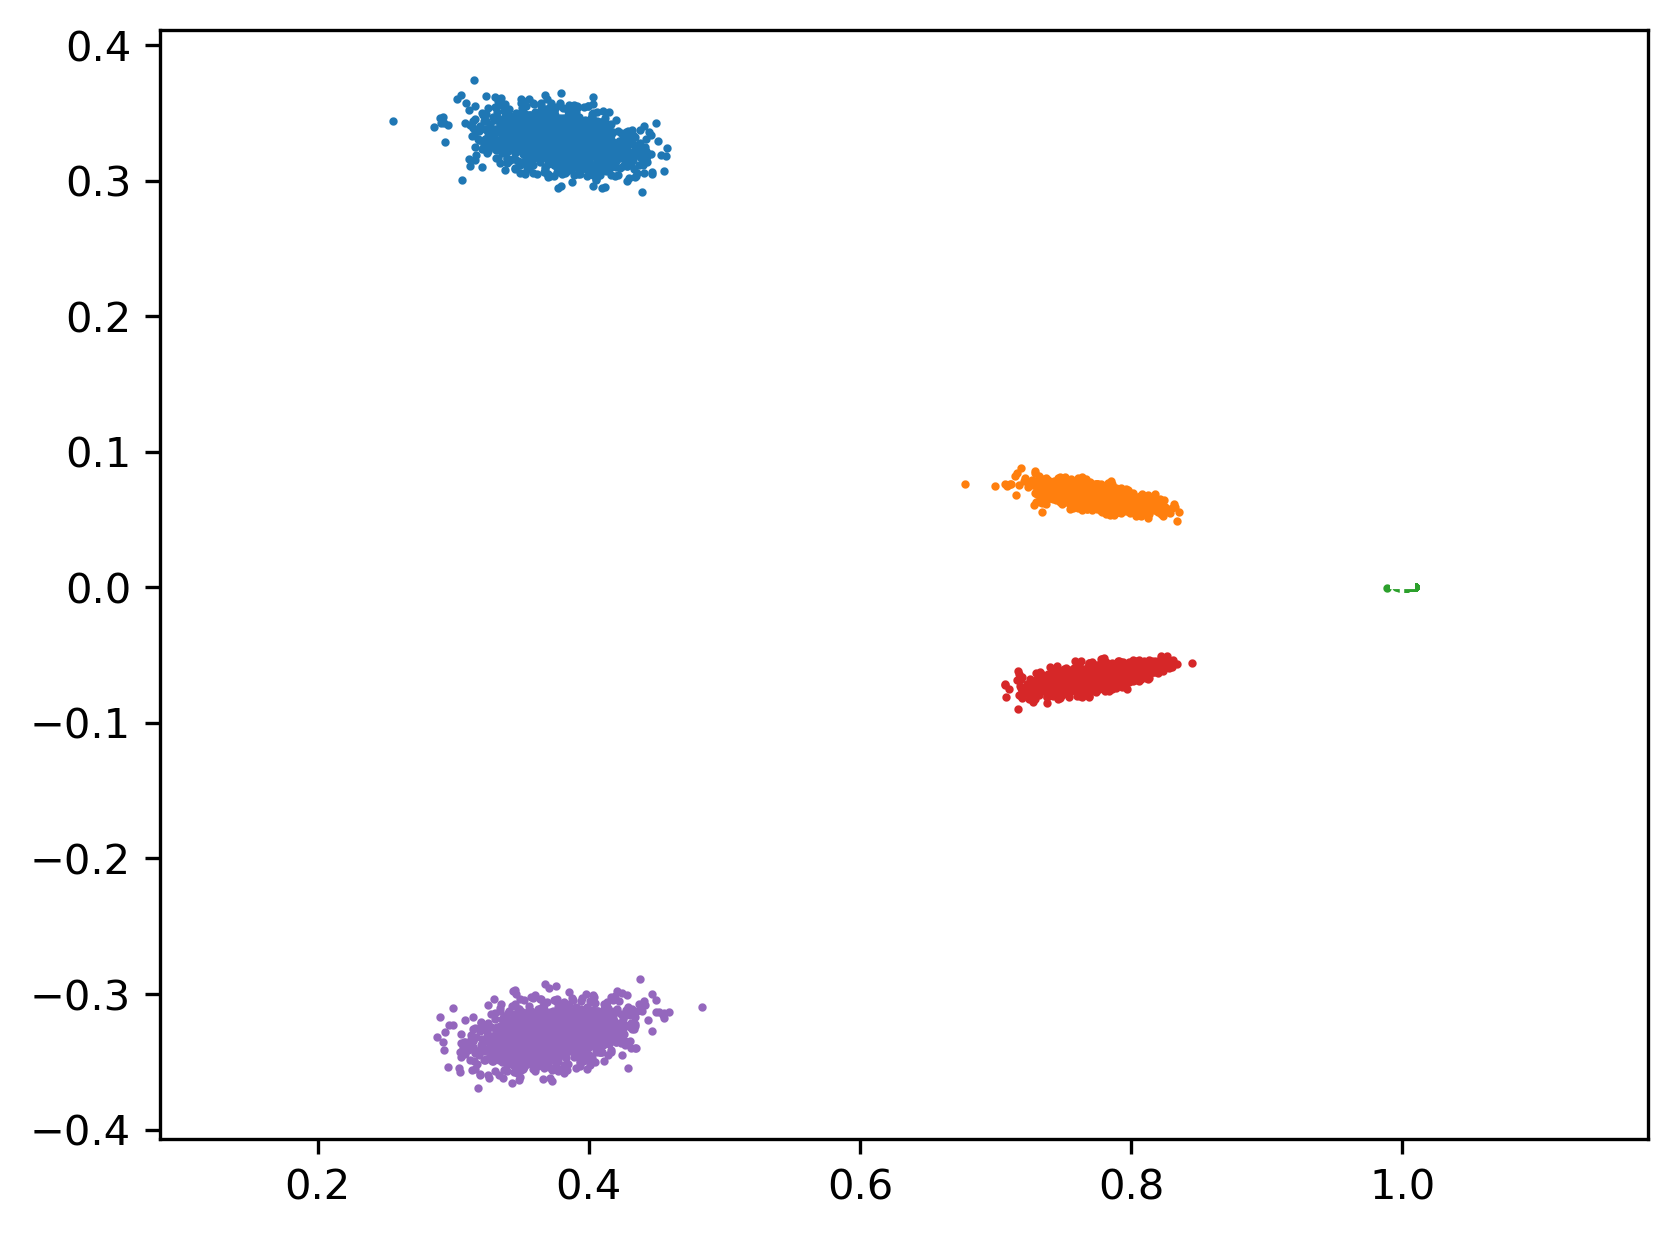

In [28]:
N = 1300
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.1,
              v = 1,
              dt = 1e-3,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]

for offset in np.linspace(-0.1,0.1, 5)*0.04:  
    params['target_slope_PHI'] = offset
    sim_res = abp_sde(0, 1, X0, params)
    x2 = sim_res['per_particle_streams']['hires'][:,0,:]
    y2 = sim_res['per_particle_streams']['hires'][:,1,:]
    
    #plt.plot(x1[...,-1].T, y1[...,-1].T, '.r', markersize=2)
    plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.', markersize=2)
    plt.plot([1],[offset], '+w')
    plt.gca().axis('equal')
plt.show()

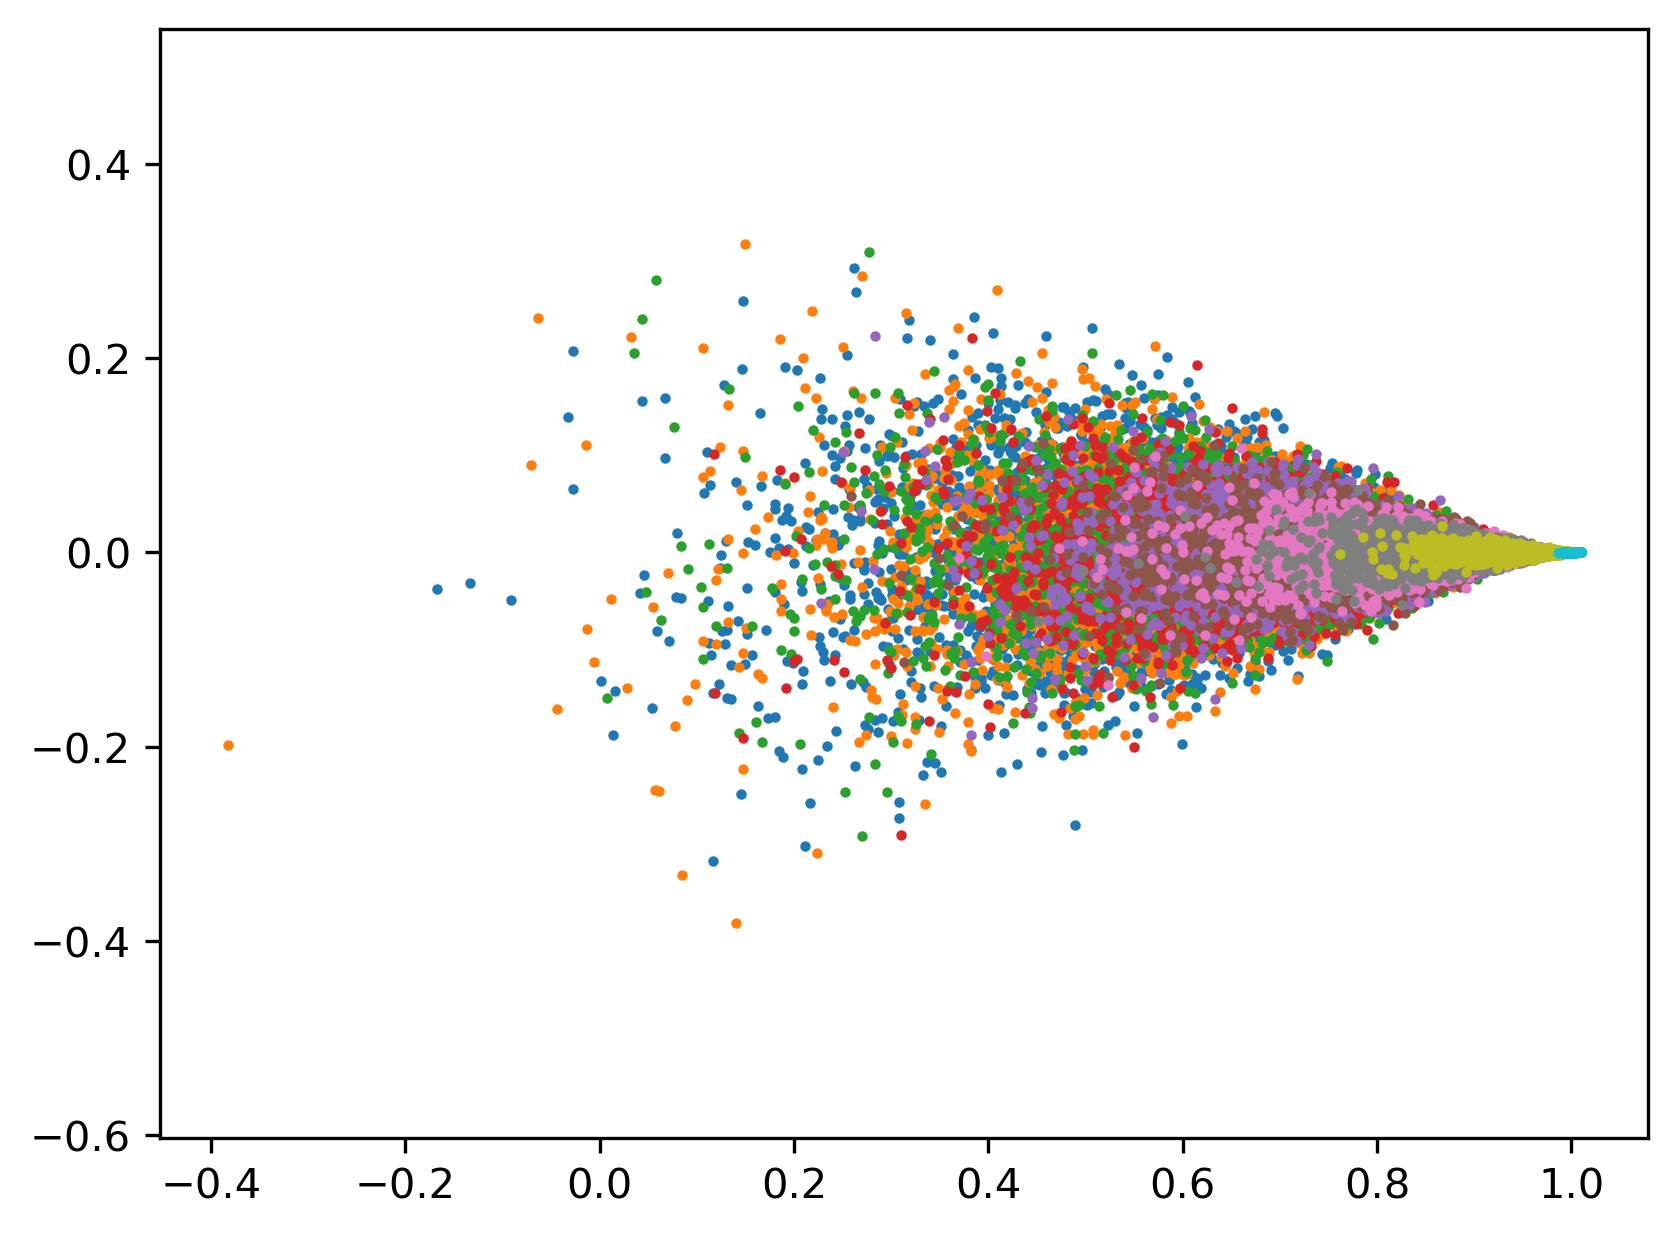

In [29]:
N = 13000
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 2,
              v = 1,
              dt = 1e-2,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1[...,-1].T, y1[...,-1].T, '.r', markersize=2)
for Dr in np.linspace(10, 0.1, 10):
    params['RNG'].reroll(0)
    params['Dr'] = Dr
    sim_res = abp_sde(0, 1, X0, params)
    x2 = sim_res['per_particle_streams']['hires'][:,0,:]
    y2 = sim_res['per_particle_streams']['hires'][:,1,:]
    plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.', markersize=3, alpha=1)
    plt.gca().axis('equal')
plt.show()